In [3]:
%pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 43.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [4]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [5]:
from ultralytics import YOLO

model = YOLO("yolo26s.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [7]:
model.info()

YOLO26s summary: 260 layers, 10,009,784 parameters, 0 gradients, 23.1 GFLOPs


(260, 10009784, 0, 23.0793216)

In [ ]:
!pip install roboflow


from roboflow import Roboflow
rf = Roboflow(api_key="YOUR_API_KEY")
project = rf.workspace("gfo-fc1de").project("fire-and-smoke-detector-yykya")
version = project.version(14)
dataset = version.download("yolo26")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 38.9 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to fire-and-smoke-detector-14 in yolo26:: 100%|██████████| 11204/11204 [00:03<00:00, 2922.75it/s]


In [9]:
results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    workers=8,
    project="/content/runs/fire_smoke",
    name="yolo26s",
    exist_ok=True
)

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fire-and-smoke-detector-14/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26s, nbs=64, nms=None, opset=None, opti

In [10]:
from pathlib import Path

RESULTS_DIR = Path(results.save_dir)

print("Results directory:", RESULTS_DIR)
print("\nGenerated files:")

for file in sorted(RESULTS_DIR.iterdir()):
    print(file.name)

Results directory: /content/runs/fire_smoke/yolo26s

Generated files:
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
args.yaml
confusion_matrix.png
confusion_matrix_normalized.png
labels.jpg
results.csv
results.png
train_batch0.jpg
train_batch1.jpg
train_batch2.jpg
train_batch9880.jpg
train_batch9881.jpg
train_batch9882.jpg
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg
weights


In [11]:
WEIGHTS_DIR = RESULTS_DIR / "weights"

for file in WEIGHTS_DIR.iterdir():
    print(f"{file.name} | {file.stat().st_size / (1024**2):.2f} MB")

last.pt | 19.37 MB
best.pt | 19.37 MB


In [12]:
from ultralytics import YOLO

best_model = YOLO(WEIGHTS_DIR / "best.pt")

test_metrics = best_model.val(
    data=f"{dataset.location}/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0
)

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,465,954 parameters, 0 gradients, 20.8 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 10.3±1.6 MB/s, size: 45.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/fire-and-smoke-detector-14/test/labels... 639 images, 72 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 639/639 505.6it/s 1.3s
val: /content/fire-and-smoke-detector-14/test/images/firesamp21_frame100_jpg.rf.45a7b54a6b0a367507eaf679be34c2fe.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: New cache created: /content/fire-and-smoke-detector-14/test/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 4, len(boxes) = 987. To resolve this only boxes will be used and all segments will be removed. To avoid this plea

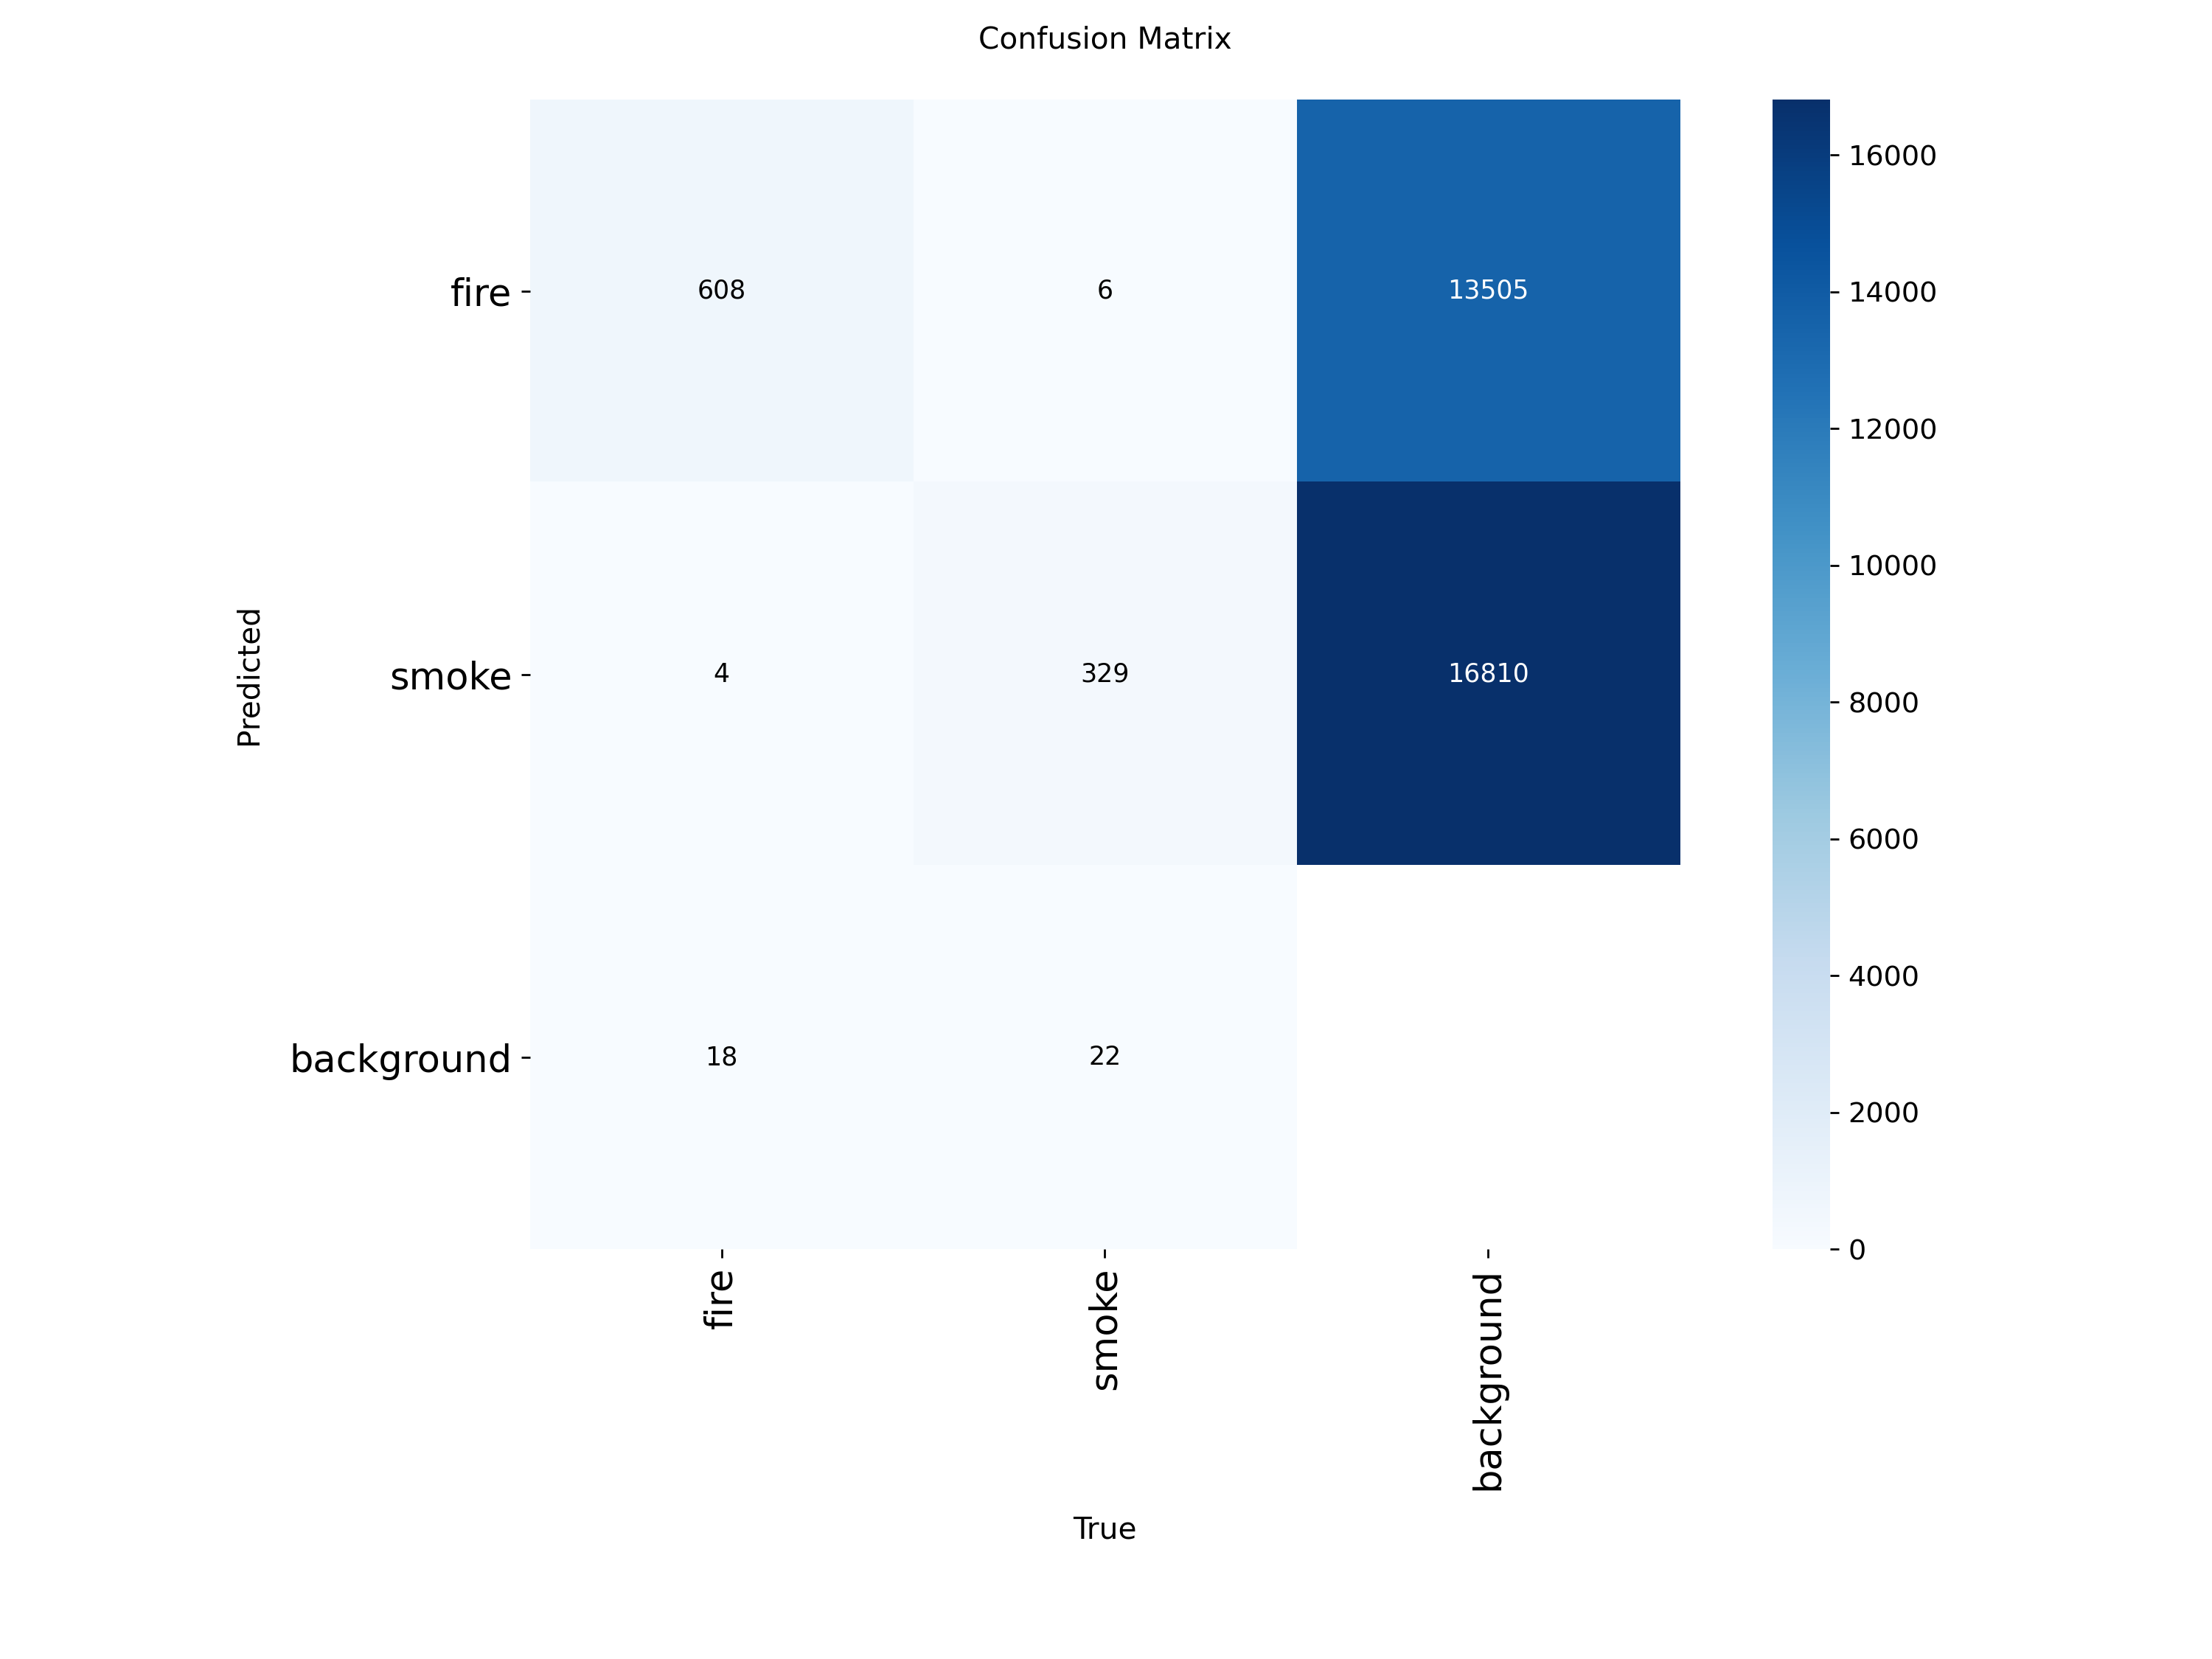

In [13]:
from IPython.display import display, Image

TEST_RESULTS_DIR = Path(test_metrics.save_dir)

display(Image(filename=str(TEST_RESULTS_DIR / "confusion_matrix.png")))

In [14]:
from google.colab import files

BEST_MODEL_PATH = WEIGHTS_DIR / "best.pt"

files.download(str(BEST_MODEL_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>